In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, k, e
from scipy.signal import correlate

from optic.comm.modulation import modulateGray
from optic.dsp.core import lowPassFIR, firFilter, upsample
from optic.models.devices import mzm
from optic.plot import eyediagram
from optic.utils import parameters

In [11]:
#%pip install OptiCommPy 
#đảm bảo tất cả các hàm toán học chuyên ngành viễn thông quang được nạp đầy đủ vào bộ nhớ để chuẩn bị gọi ra ở các bước tiếp theo.

In [12]:
# 1. Khai báo bộ đối tượng tham số
param = parameters() 

# Tham số tín hiệu & Thời gian
param.Rs = 10e9          # Tốc độ ký hiệu: 10 GBaud (10 Gbps với OOK)
param.SpS = 16           # Số mẫu trên 1 ký hiệu (Samples per symbol)
param.Fs = param.Rs * param.SpS  # Tần số lấy mẫu (160 GHz)
param.Nbits = 2**14      # Tổng số bit mô phỏng (16,384 bits)

# Tham số Bộ điều chế Quang MZM (Khối phát)
param.Vpi = 2.0          # Điện áp Vpi = 2V
param.Vb = -1.0          # Điện áp Bias = -1V
P_tx_dBm = 0             # Công suất quang phát: 0 dBm (1 mW)
P_tx_mW = 10**(P_tx_dBm/10)

# Tham số Kênh truyền Sợi quang (Fiber Channel)
param.L = 20             # Chiều dài sợi quang: L km
param.alpha = 0.2        # Hệ số suy hao: 0.2 dB/km
param.D = 16.0           # Hệ số tán sắc sắc thể: 16 ps/nm/km
param.wavelength = 1550e-9 # Bước sóng hoạt động: 1550 nm

# Tham số Bộ thu Quang Photodiode & Nhiễu (Receiver)
param.R = 0.85           # Trách nhiệm quang (Responsivity) = 0.85 A/W
param.B = 0.75 * param.Rs # Băng thông bộ thu = 7.5 GHz
T_temp = 300             # Nhiệt độ môi trường = 300 K
R_load = 50              # Trở kháng tải = 50 Ohm

print("==================================================")
print("     BỘ THAM SỐ MÔ PHỎNG HỆ THỐNG IM-DD (OOK)")
print("==================================================")
print(f"• Tốc độ bit (Bitrate):          {param.Rs/1e9:.1f} Gbps")
print(f"• Tần số lấy mẫu (Fs):           {param.Fs/1e9:.1f} GHz")
print(f"• Bước sóng quang (wavelength):  {param.wavelength*1e9:.0f} nm")
print(f"• Chiều dài sợi quang (L):       {param.L} km")
print(f"• Suy hao sợi quang (alpha):     {param.alpha} dB/km")
print(f"• Tán sắc sắc thể (D):          {param.D} ps/nm/km")
print(f"• Băng thông bộ thu (B):         {param.B/1e9:.2f} GHz")
print("==================================================")

     BỘ THAM SỐ MÔ PHỎNG HỆ THỐNG IM-DD (OOK)
• Tốc độ bit (Bitrate):          10.0 Gbps
• Tần số lấy mẫu (Fs):           160.0 GHz
• Bước sóng quang (wavelength):  1550 nm
• Chiều dài sợi quang (L):       20 km
• Suy hao sợi quang (alpha):     0.2 dB/km
• Tán sắc sắc thể (D):          16.0 ps/nm/km
• Băng thông bộ thu (B):         7.50 GHz



--------------------------------------------------
1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT (TRANSMITTER)
--------------------------------------------------
• Công suất quang phát đỉnh (Peak Tx Power): 0.962 mW
• Công suất quang phát trung bình:           0.494 mW (-3.06 dBm)


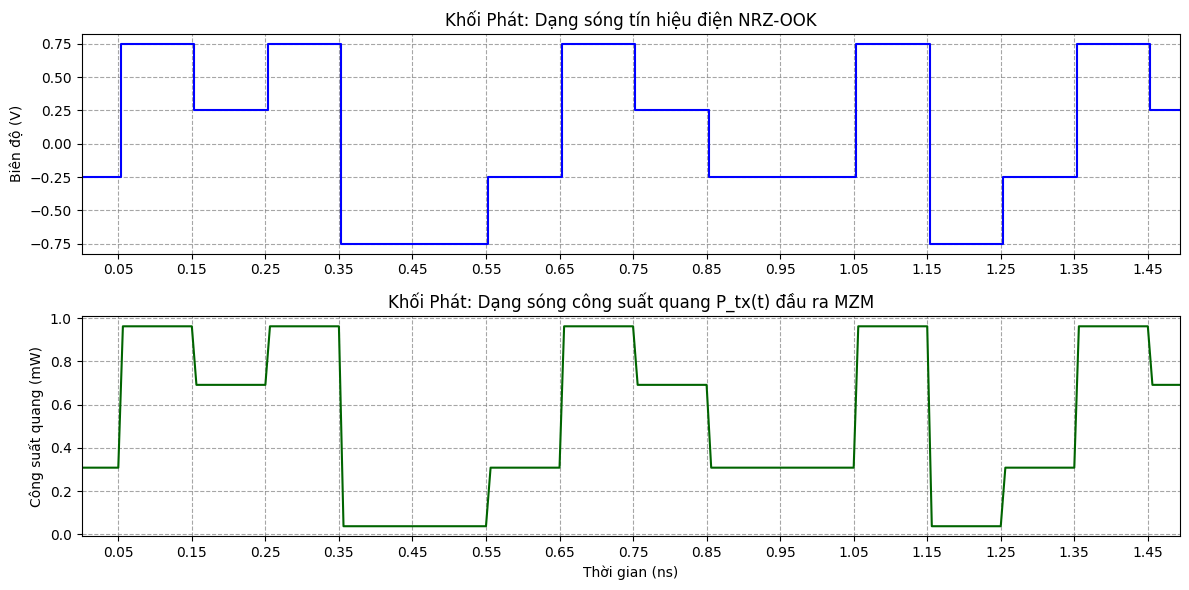

In [13]:
# --- QUÁ TRÌNH XỬ LÝ KHỐI PHÁT ---
# 1. Tạo chuỗi bit ngẫu nhiên
bitsTx = np.random.randint(0, 2, param.Nbits)

# 2. Điều chế chuỗi bit thành dạng sóng điện NRZ
symbTx = modulateGray(bitsTx, 4, 'pam')
symbUp = upsample(symbTx, param.SpS)
p = np.ones(param.SpS) / np.sqrt(param.SpS)
sigTx_elec = firFilter(p, symbUp)

# 3. Mã hóa tín hiệu điện sang dạng sóng quang qua MZM
Ai = np.sqrt(P_tx_mW * 1e-3)
E_tx = mzm(Ai, sigTx_elec, param)

# --- TÍNH TOÁN SỐ LIỆU KHỐI PHÁT ---
P_tx_instant = np.abs(E_tx)**2
P_tx_avg = np.mean(P_tx_instant)
P_tx_avg_dBm = 10 * np.log10(P_tx_avg / 1e-3)

print("\n--------------------------------------------------")
print("1. KẾT QUẢ SỐ LIỆU TÍNH TOÁN KHỐI PHÁT (TRANSMITTER)")
print("--------------------------------------------------")
print(f"• Công suất quang phát đỉnh (Peak Tx Power): {np.max(P_tx_instant)*1e3:.3f} mW")
print(f"• Công suất quang phát trung bình:           {P_tx_avg*1e3:.3f} mW ({P_tx_avg_dBm:.2f} dBm)")

# --- VẼ ĐỒ THỊ DẠNG SÓNG KHỐI PHÁT ---
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
N_disp = 15 * param.SpS
t_ns = np.arange(N_disp) / param.Fs * 1e9

Tb_ns = (1 / param.Rs) * 1e9  
bit_ticks = np.arange(0.05, t_ns[-1] + Tb_ns/2, Tb_ns)  # Tạo vạch chia [0.0, 0.1, 0.2, ..., 1.5] ns

ax[0].step(t_ns, sigTx_elec[:N_disp], color='blue', where='mid')
ax[0].set_title("Khối Phát: Dạng sóng tín hiệu điện NRZ-OOK")
ax[0].set_ylabel("Biên độ (V)")
ax[0].grid(True)

ax[1].plot(t_ns, P_tx_instant[:N_disp]*1e3, color='darkgreen')
ax[1].set_title("Khối Phát: Dạng sóng công suất quang P_tx(t) đầu ra MZM")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Công suất quang (mW)")
ax[1].grid(True)

for a in ax:
    a.set_xticks(bit_ticks) # Ép Matplotlib hiển thị các vạch mốc (ticks) trên trục hoành X trùng khít với mảng thời gian bit_ticks ($0.1\text{ ns}$ mỗi vạch). 
    a.set_xlim([0, t_ns[-1]]) #Khóa chiều dài trục X vừa vặn từ $0$ đến $1.5\text{ ns}$, cắt bỏ phần khoảng trắng thừa ở 2 đầu mép đồ thị.
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')

plt.tight_layout()
plt.show()

In [14]:
np.ones(param.SpS)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


--------------------------------------------------
2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG (FIBER CHANNEL)
--------------------------------------------------
• Suy hao tổng của cự ly 20 km:             4.00 dB
• Công suất quang thu được tại cuối sợi:    0.1968 mW (-7.06 dBm)
• Trường quang cực đại:                     0.024+0.001j
• Công suất quang thu đỉnh (Peak Rx Power): 0.560 mW


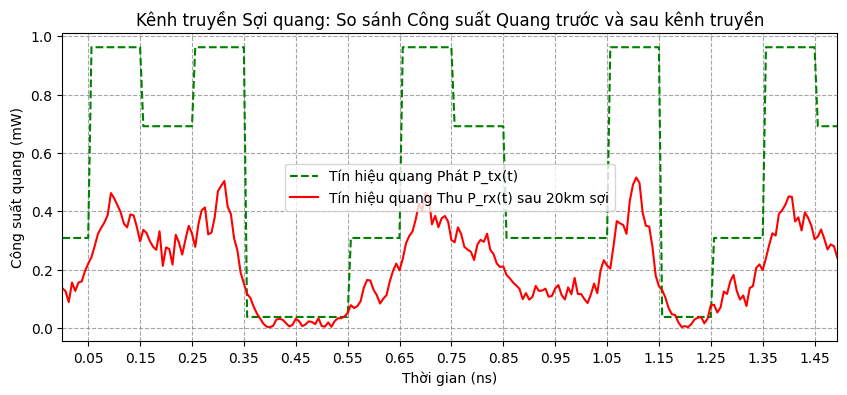

In [15]:
# --- QUÁ TRÌNH XỬ LÝ KÊNH TRUYỀN SỢI QUANG ---
# 1. Tính toán tham số vật lý của sợi quang
alpha_rad = param.alpha / (10 * np.log10(np.e) * 1e3) # Chuyển dB/km sang 1/m
beta2 = -(param.wavelength**2 / (2 * np.pi * c)) * (param.D * 1e-6) # s^2/m
Total_Loss_dB = param.alpha * param.L

# 2. Truyền tín hiệu quang trong miền tần số (Tán sắc & Suy hao)
N_samples = len(E_tx)
freq = np.fft.fftfreq(N_samples, 1/param.Fs)
omega = 2 * np.pi * freq

H_fiber = np.exp(-alpha_rad * (param.L * 1e3) / 2) * np.exp(+1j * (beta2 / 2) * (omega**2) * (param.L * 1e3))
E_rx_optical = np.fft.ifft(np.fft.fft(E_tx) * H_fiber)

# --- TÍNH TOÁN SỐ LIỆU KÊNH TRUYỀN ---
P_rx_optical = np.abs(E_rx_optical)**2
P_rx_avg = np.mean(P_rx_optical)
P_rx_avg_dBm = 10 * np.log10(P_rx_avg / 1e-3)

print("\n--------------------------------------------------")
print("2. KẾT QUẢ SỐ LIỆU KÊNH TRUYỀN SỢI QUANG (FIBER CHANNEL)")
print("--------------------------------------------------")
print(f"• Suy hao tổng của cự ly {param.L} km:             {Total_Loss_dB:.2f} dB")
print(f"• Công suất quang thu được tại cuối sợi:    {P_rx_avg*1e3:.4f} mW ({P_rx_avg_dBm:.2f} dBm)")
print(f"• Trường quang cực đại:                     {np.max(E_rx_optical):.3f}")
print(f"• Công suất quang thu đỉnh (Peak Rx Power): {np.max(P_rx_optical)*1e3:.3f} mW")

# --- VẼ ĐỒ THỊ SO SÁNH KÊNH TRUYỀN ---
Tb_ns = (1 / param.Rs) * 1e9  
bit_ticks = np.arange(0.05, t_ns[-1] + Tb_ns/2, Tb_ns)  # Tạo vạch chia [0.0, 0.1, 0.2, ..., 1.5] ns

plt.figure(figsize=(10, 4))
plt.plot(t_ns, P_tx_instant[:N_disp]*1e3, label='Tín hiệu quang Phát P_tx(t)', color='green', linestyle='--')
plt.plot(t_ns, P_rx_optical[:N_disp]*1e3, label=f'Tín hiệu quang Thu P_rx(t) sau {param.L}km sợi', color='red')
plt.title("Kênh truyền Sợi quang: So sánh Công suất Quang trước và sau kênh truyền")
plt.xlabel("Thời gian (ns)")
plt.ylabel("Công suất quang (mW)")
plt.legend()
plt.grid(True)

for a in plt.gcf().axes:
    a.set_xticks(bit_ticks) # Ép Matplotlib hiển thị các vạch mốc (ticks) trên trục hoành X trùng khít với mảng thời gian bit_ticks ($0.1\text{ ns}$ mỗi vạch). 
    a.set_xlim([0, t_ns[-1]]) #Khóa chiều dài trục X vừa vặn từ $0$ đến $1.5\text{ ns}$, cắt bỏ phần khoảng trắng thừa ở 2 đầu mép đồ thị.
    a.grid(True, which='both', linestyle='--', alpha=0.7, color='gray')
    
plt.show()

In [16]:
# ==========================================
# TÍNH CHIỀU DÀI SUY HAO VÀ CHIỀU DÀI TÁN SẮC
# ==========================================
# 1. Chiều dài suy hao L_alpha
alpha_np = param.alpha / (10 * np.log10(np.e))  # 1/km
L_alpha = 1 / alpha_np                          # km

# 2. Chiều dài tán sắc L_D
#beta2 = -(param.wavelength**2 / (2 * np.pi * c)) * (param.D * 1e-6)  # s^2/m
T0 = 1 / param.Rs                                                     # thời lượng 1 bit (s)
L_D_m = (T0**2) / np.abs(beta2)                                       # m
L_D_km = L_D_m / 1e3                                                  # km

print("--------------------------------------------------")
print("PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG")
print("--------------------------------------------------")
print(f"• Chiều dài suy hao (L_alpha): {L_alpha:.2f} km")
print(f"• Hệ số GVD (beta2):         {beta2*1e27:.2f} (ps)^2/km")
print(f"• Chiều dài tán sắc (L_D):     {L_D_km:.2f} km")
print("--------------------------------------------------")

--------------------------------------------------
PHÂN TÍCH ĐẶC TÍNH KÊNH TRUYỀN SỢI QUANG
--------------------------------------------------
• Chiều dài suy hao (L_alpha): 21.71 km
• Hệ số GVD (beta2):         -20.41 (ps)^2/km
• Chiều dài tán sắc (L_D):     490.02 km
--------------------------------------------------



--------------------------------------------------
3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (RECEIVER & NOISE)
--------------------------------------------------
• Dòng quang điện trung bình (I_dc):         167.28 uA
• Độ lệch chuẩn Nhiễu hạt (Shot noise):      0.6340 uA
• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  1.5764 uA
• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   36.63 dB


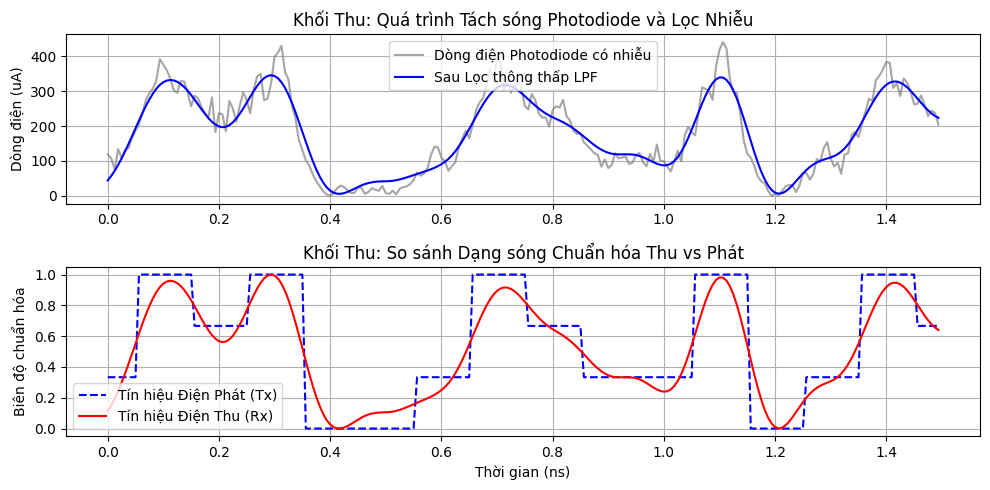


--------------------------------------------------
4. ĐÁNH GIÁ EYE DIAGRAM & BER
--------------------------------------------------


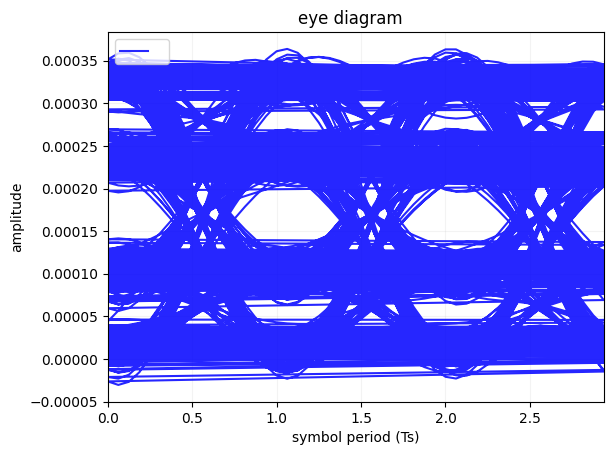

IndexError: boolean index did not match indexed array along axis 0; size of axis is 8192 but size of corresponding boolean axis is 16384

In [17]:
# --- QUÁ TRÌNH XỬ LÝ KHỐI THU ---
# 1. Tách sóng quang thành Dòng điện (Photodiode PIN)
from math import erfc
I_dc_pure = param.R * P_rx_optical

# 2. Thêm 2 loại nhiễu vật lý tại phía thu
# A. Nhiễu hạt (Shot noise)
sigma2_shot = 2 * e * np.mean(I_dc_pure) * param.B
noise_shot = np.random.normal(0, np.sqrt(sigma2_shot), N_samples)

# B. Nhiễu nhiệt (Thermal noise)
sigma2_thermal = (4 * k * T_temp / R_load) * param.B
noise_thermal = np.random.normal(0, np.sqrt(sigma2_thermal), N_samples)

I_rx_noisy = I_dc_pure + noise_shot + noise_thermal

# 3. Bộ lọc thông thấp LPF loại bỏ nhiễu cao tần
h_lpf = lowPassFIR(fc=0.75*param.Rs, fa=param.Fs, N=64)
I_filt = firFilter(h_lpf, I_rx_noisy)


# --- TÍNH TOÁN SỐ LIỆU KHỐI THU ---
SNR_rx = 10 * np.log10(np.var(I_dc_pure) / (sigma2_shot + sigma2_thermal))

print("\n--------------------------------------------------")
print("3. KẾT QUẢ SỐ LIỆU KHỐI THU & NHIỄU (RECEIVER & NOISE)")
print("--------------------------------------------------")
print(f"• Dòng quang điện trung bình (I_dc):         {np.mean(I_dc_pure)*1e6:.2f} uA")
print(f"• Độ lệch chuẩn Nhiễu hạt (Shot noise):      {np.sqrt(sigma2_shot)*1e6:.4f} uA")
print(f"• Độ lệch chuẩn Nhiễu nhiệt (Thermal noise):  {np.sqrt(sigma2_thermal)*1e6:.4f} uA")
print(f"• Tỷ số Tín hiệu trên Nhiễu điện (SNR_el):   {SNR_rx:.2f} dB")

# --- VẼ ĐỒ THỊ KHỐI THU (DẠNG SÓNG) ---
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(t_ns, I_rx_noisy[:N_disp]*1e6, color='gray', alpha=0.7, label='Dòng điện Photodiode có nhiễu')
ax[0].plot(t_ns, I_filt[:N_disp]*1e6, color='blue', linewidth=1.5, label='Sau Lọc thông thấp LPF')
ax[0].set_title("Khối Thu: Quá trình Tách sóng Photodiode và Lọc Nhiễu")
ax[0].set_ylabel("Dòng điện (uA)")
ax[0].legend()
ax[0].grid(True)

sigTx_norm = (sigTx_elec[:N_disp] - np.min(sigTx_elec[:N_disp])) / np.ptp(sigTx_elec[:N_disp])
I_filt_norm = (I_filt[:N_disp] - np.min(I_filt[:N_disp])) / np.ptp(I_filt[:N_disp])

ax[1].plot(t_ns, sigTx_norm, label='Tín hiệu Điện Phát (Tx)', linestyle='--', color='blue')
ax[1].plot(t_ns, I_filt_norm, label='Tín hiệu Điện Thu (Rx)', color='red')
ax[1].set_title("Khối Thu: So sánh Dạng sóng Chuẩn hóa Thu vs Phát")
ax[1].set_xlabel("Thời gian (ns)")
ax[1].set_ylabel("Biên độ chuẩn hóa")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

# --- ĐÁNH GIÁ KẾT QUẢ ĐỒ ÁN: BIỂU ĐỒ MẮT & KHẢO SÁT BER ---
print("\n--------------------------------------------------")
print("4. ĐÁNH GIÁ EYE DIAGRAM & BER")
print("--------------------------------------------------")

# A. Biểu đồ mắt (Eye Diagram) tại cự ly L = 20 km (Không tạo khung thừa)
eyediagram(I_filt, 1000 * param.SpS, param.SpS, n=3)
#plt.title(f"Eye Diagram - Tuyến IM-DD/OOK (L = {param.L} km, D = {param.D} ps/nm/km)")
plt.show()

# captures samples in the middle of signaling intervals
I_Rx  = I_filt[0::param.SpS]

# obtains statistics of the received signal

I1 = np.mean(I_Rx[bitsTx==1]) # average value of I1
I0 = np.mean(I_Rx[bitsTx==0]) # average value of I0

σ1 = np.std(I_Rx[bitsTx==1]) # standard deviation σ1 of I1
σ0 = np.std(I_Rx[bitsTx==0]) # standard deviation σ0 of I0

Id = (σ1*I0 + σ0*I1)/(σ1 + σ0) # optimal decision threshold
Q  = (I1-I0)/(σ1 + σ0)         # Q factor

print('-----Thông số Eye diagram-----')
print('• Dòng trung bình bit 1 (I1) = %.8f'%(I1))
print('• Dòng trung bình bit 0 (I0) = %.8f'%(I0))
print('• Độ lệch chuẩn bit 1 (σ1) = %.8f'%(σ1))
print('• Độ lệch chuẩn bit 0 (σ0) = %.8f'%(σ0))
print('• Ngưỡng quyết định tối ưu (Id) = %.8f'%(Id))
print('• FACTOR Q = %.8f \n'%(Q))

# Apply the optimal decision rule
bitsRx = np.empty(bitsTx.size)
bitsRx[I_Rx>  Id] = 1
bitsRx[I_Rx<= Id] = 0

#discard = 100
#err = np.logical_xor(bitsRx[discard:bitsRx.size-discard], bitsTx[discard:bitsTx.size-discard])
err = np.logical_xor(bitsRx, bitsTx)
BER = np.mean(err)

Pb = 0.5*erfc(Q/np.sqrt(2)) # theoretical error probability
print('----------THÔNG SỐ BER----------')
print('• Tổng bit lỗi đếm được = %d'%(err.sum()))
print('• BER = %.8e'%(BER))
print('• Pb = %.8e'%(Pb))



In [ ]:
I_shot=np.sqrt(sigma2_shot)
I_ther=np.sqrt(sigma2_thermal)
Id = (I_shot*sigma2_shot + I_ther*sigma2_thermal)/(sigma2_shot + sigma2_thermal) #công thức tính ngưỡng này bị sai cần xem lại
I_shot

np.float64(6.383272407084605e-07)

In [ ]:
g=np.mean(I_dc_pure)
g


np.float64(0.00016954504581816158)

In [ ]:
I_dc_pure
#noise_shot
#sigma2_shot
#sigma2_thermal
np.var(I_dc_pure)

#bitsRx

np.float64(3.855977615473254e-09)


--------------------------------------------------
5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) THEO CỰ LY SỢI QUANG
--------------------------------------------------


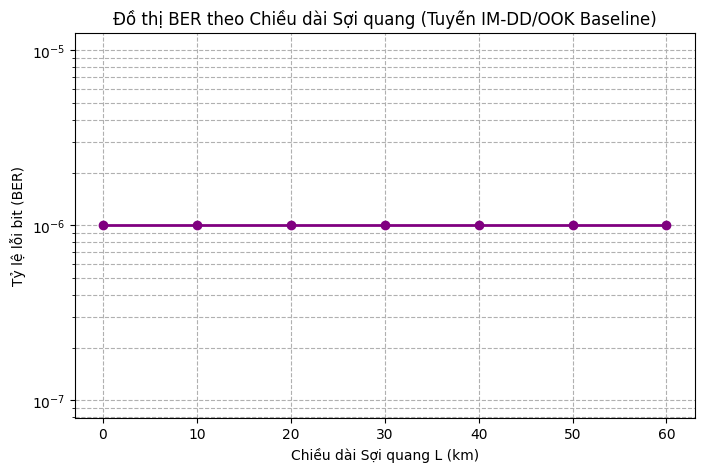

In [ ]:
# B. Khảo sát BER theo các cự ly sợi quang L = [0, 10, 20, 30, 40, 50, 60] km
print("\n--------------------------------------------------")
print("5. KHẢO SÁT TỶ LỆ LỖI BIT (BER) THEO CỰ LY SỢI QUANG")
print("--------------------------------------------------")
L_vec = np.linspace(0, 60, 7)
BER_list = []
#N_corr = 1000 * param.SpS
N_corr = N_samples

for L_i in L_vec:
    H_fiber_i = np.exp(-alpha_rad * (L_i * 1e3) / 2) * np.exp(1j * (beta2 / 2) * (omega**2) * (L_i * 1e3))
    E_rx_i = np.fft.ifft(np.fft.fft(E_tx) * H_fiber_i)
    
    I_dc_i = param.R * np.abs(E_rx_i)**2
    n_shot_i = np.random.normal(0, np.sqrt(2 * e * np.mean(I_dc_i) * param.B), N_samples)
    n_therm_i = np.random.normal(0, np.sqrt((4 * k * T_temp / R_load) * param.B), N_samples)
    
    I_filt_i = firFilter(h_lpf, I_dc_i + n_shot_i + n_therm_i)
    
    # Đồng bộ tín hiệu bằng FFT
    corr = correlate(I_filt_i[:N_corr] - np.mean(I_filt_i[:N_corr]), sigTx_elec[:N_corr] - np.mean(sigTx_elec[:N_corr]), method='fft')
    delay = np.argmax(corr) - (N_corr - 1)
    
    I_sampled = I_filt_i[delay :: param.SpS][:len(bitsTx)]
    threshold = (np.max(I_sampled) + np.min(I_sampled)) / 2
    bitsRx = (I_sampled > threshold).astype(int)
    
    ber = min(np.mean(bitsTx != bitsRx), np.mean(bitsTx != (1 - bitsRx)))
    BER_list.append(max(ber, 1e-6)) #đặt mức sàn 10(-6) để tránh log(0) khi vẽ đồ thị BER

# Drawing BER plot
plt.figure(figsize=(8, 5))
plt.semilogy(L_vec, BER_list, 'o-', color='purple', linewidth=2, markersize=6)
plt.xlabel('Chiều dài Sợi quang L (km)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title('Đồ thị BER theo Chiều dài Sợi quang (Tuyến IM-DD/OOK Baseline)')
plt.grid(True, which="both", ls="--")
plt.show()